# Date Fruit Classification

Classify date fruit varieties from numerical measurements.

See [README.md](README.md) for data, setup, workflow, and evaluation notes.

In [1]:
import random
import numpy as np
import torch
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(4)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv("date_fruit.csv")

In [4]:
df.head() #34 features,1 Category

,AREA,PERIMETER,MAJOR_AXIS,MINOR_AXIS,ECCENTRICITY,EQDIASQ,SOLIDITY,CONVEX_AREA,EXTENT,ASPECT_RATIO,...,KurtosisRR,KurtosisRG,KurtosisRB,EntropyRR,EntropyRG,EntropyRB,ALLdaub4RR,ALLdaub4RG,ALLdaub4RB,Class
0,422163,2378.908,837.8484,645.6693,0.6373,733.1539,0.9947,424428,0.7831,1.2976,...,3.2370,2.9574,4.2287,-59191263232,-50714214400,-39922372608,58.7255,54.9554,47.8400,BERHI
1,338136,2085.144,723.8198,595.2073,0.5690,656.1464,0.9974,339014,0.7795,1.2161,...,2.6228,2.6350,3.1704,-34233065472,-37462601728,-31477794816,50.0259,52.8168,47.8315,BERHI
2,526843,2647.394,940.7379,715.3638,0.6494,819.0222,0.9962,528876,0.7657,1.3150,...,3.7516,3.8611,4.7192,-93948354560,-74738221056,-60311207936,65.4772,59.2860,51.9378,BERHI
3,416063,2351.210,827.9804,645.2988,0.6266,727.8378,0.9948,418255,0.7759,1.2831,...,5.0401,8.6136,8.2618,-32074307584,-32060925952,-29575010304,43.3900,44.1259,41.1882,BERHI
4,347562,2160.354,763.9877,582.8359,0.6465,665.2291,0.9908,350797,0.7569,1.3108,...,2.7016,2.9761,4.4146,-39980974080,-35980042240,-25593278464,52.7743,50.9080,42.6666,BERHI


In [5]:
df.shape

(898, 35)

In [6]:
df.isnull().sum()

AREA             0
PERIMETER        0
MAJOR_AXIS       0
MINOR_AXIS       0
ECCENTRICITY     0
EQDIASQ          0
SOLIDITY         0
CONVEX_AREA      0
EXTENT           0
ASPECT_RATIO     0
ROUNDNESS        0
COMPACTNESS      0
SHAPEFACTOR_1    0
SHAPEFACTOR_2    0
SHAPEFACTOR_3    0
SHAPEFACTOR_4    0
MeanRR           0
MeanRG           0
MeanRB           0
StdDevRR         0
StdDevRG         0
StdDevRB         0
SkewRR           0
SkewRG           0
SkewRB           0
KurtosisRR       0
KurtosisRG       0
KurtosisRB       0
EntropyRR        0
EntropyRG        0
EntropyRB        0
ALLdaub4RR       0
ALLdaub4RG       0
ALLdaub4RB       0
Class            0
dtype: int64

In [7]:
X = df.drop("Class",axis=1)
y = df["Class"]

In [8]:
df["Class"].unique()

<ArrowStringArray>
['BERHI', 'DEGLET', 'DOKOL', 'IRAQI', 'ROTANA', 'SAFAVI', 'SOGAY']
Length: 7, dtype: str

In [9]:
from sklearn.preprocessing import StandardScaler,LabelEncoder

le = LabelEncoder()
y = le.fit_transform(y)

In [10]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y
)

In [11]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [12]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [13]:
print("Original features:", X_train_scaled.shape[1])
print("PCA features:", X_train_pca.shape[1])

Original features: 34
PCA features: 9


In [14]:
#ANN
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader,TensorDataset

In [15]:
X_train_tensor = torch.tensor(X_train_pca,dtype=torch.float32)
y_train_tensor = torch.tensor(y_train,dtype=torch.long)

X_test_tensor = torch.tensor(X_test_pca,dtype=torch.float32)
y_test_tensor = torch.tensor(y_test,dtype=torch.long)

In [16]:
train_dataset = TensorDataset(X_train_tensor,y_train_tensor)
test_dataset = TensorDataset(X_test_tensor,y_test_tensor)

In [17]:
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader = DataLoader(test_dataset,batch_size=32)

In [18]:
#Build our Model

class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()

        self.model = nn.Sequential(
            nn.Linear(X_train_pca.shape[1],64),
            nn.ReLU(),

            nn.Linear(64,64),
            nn.ReLU(),

            nn.Linear(64,7)
        )

    def forward(self,x):
        return self.model(x)

In [19]:
model = ANN()

#loss & optimizer

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

In [20]:
#Training the NN

epochs = 100
train_losses = []

for epoch in range(epochs):
    model.train()

    running_loss = 0.0

    for xb,yb in train_loader:

        optimizer.zero_grad()
        
        outputs = model(xb)
        loss = criterion(outputs,yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * xb.size(0)

    training_loss = running_loss/len(train_dataset)

    train_losses.append(training_loss)
    print(f"epoch = {epoch + 1}/{epochs} , loss = {training_loss}")

epoch = 1/100 , loss = 1.5803926545597384
epoch = 2/100 , loss = 1.0470356368420848
epoch = 3/100 , loss = 0.7396398322827968
epoch = 4/100 , loss = 0.5773105121588641
epoch = 5/100 , loss = 0.4869509868967168
epoch = 6/100 , loss = 0.4217218464463534
epoch = 7/100 , loss = 0.37937083433597535
epoch = 8/100 , loss = 0.3370986760160717
epoch = 9/100 , loss = 0.31148280423331726
epoch = 10/100 , loss = 0.28762413876800486
epoch = 11/100 , loss = 0.27355222213069047
epoch = 12/100 , loss = 0.2543471119363992
epoch = 13/100 , loss = 0.2398242103273158


epoch = 14/100 , loss = 0.22984147092592086
epoch = 15/100 , loss = 0.22187371543689027
epoch = 16/100 , loss = 0.2092324885692769
epoch = 17/100 , loss = 0.202506960849576
epoch = 18/100 , loss = 0.19621609505214066
epoch = 19/100 , loss = 0.18862698247920837
epoch = 20/100 , loss = 0.18362986925252633
epoch = 21/100 , loss = 0.17806273445611545
epoch = 22/100 , loss = 0.17249759193250397
epoch = 23/100 , loss = 0.1720626437232355
epoch = 24/100 , loss = 0.16862103141698997
epoch = 25/100 , loss = 0.1628355990711361
epoch = 26/100 , loss = 0.15165932787826134
epoch = 27/100 , loss = 0.15073623003899886


epoch = 28/100 , loss = 0.1505958325642065
epoch = 29/100 , loss = 0.14901054241697104
epoch = 30/100 , loss = 0.14369918265922155
epoch = 31/100 , loss = 0.13680038648893575
epoch = 32/100 , loss = 0.14252294047961328
epoch = 33/100 , loss = 0.1346447750261899
epoch = 34/100 , loss = 0.13625085554124586
epoch = 35/100 , loss = 0.13025172943026242
epoch = 36/100 , loss = 0.12392504486283884
epoch = 37/100 , loss = 0.12367157175265314
epoch = 38/100 , loss = 0.1184305878755608
epoch = 39/100 , loss = 0.11690539769143447
epoch = 40/100 , loss = 0.11366523997365266


epoch = 41/100 , loss = 0.11191218605778676
epoch = 42/100 , loss = 0.11215285489901194
epoch = 43/100 , loss = 0.10797887687729593
epoch = 44/100 , loss = 0.10911119487499792
epoch = 45/100 , loss = 0.10265440562309329
epoch = 46/100 , loss = 0.10564262538235168
epoch = 47/100 , loss = 0.1058166316375759
epoch = 48/100 , loss = 0.10458069869568754
epoch = 49/100 , loss = 0.10649248358889543
epoch = 50/100 , loss = 0.10823177295142894
epoch = 51/100 , loss = 0.09808078148819942
epoch = 52/100 , loss = 0.0936935083074158
epoch = 53/100 , loss = 0.09551287120763306


epoch = 54/100 , loss = 0.09062779966669163
epoch = 55/100 , loss = 0.09262723735115987
epoch = 56/100 , loss = 0.09044913944469189
epoch = 57/100 , loss = 0.0874504351516288
epoch = 58/100 , loss = 0.08667644351969854
epoch = 59/100 , loss = 0.08308831700915081
epoch = 60/100 , loss = 0.08093327464416498
epoch = 61/100 , loss = 0.08341674205735533
epoch = 62/100 , loss = 0.08033174981977946
epoch = 63/100 , loss = 0.07931456970139135
epoch = 64/100 , loss = 0.07572407302418127
epoch = 65/100 , loss = 0.07884859211722124
epoch = 66/100 , loss = 0.07519109049049261
epoch = 67/100 , loss = 0.07061800788205978


epoch = 68/100 , loss = 0.0717582651582601
epoch = 69/100 , loss = 0.0703011262995868
epoch = 70/100 , loss = 0.06906256354141534
epoch = 71/100 , loss = 0.0734743513270673
epoch = 72/100 , loss = 0.06710693570149642
epoch = 73/100 , loss = 0.06308142628136784
epoch = 74/100 , loss = 0.06451419363457263
epoch = 75/100 , loss = 0.06206264900961958
epoch = 76/100 , loss = 0.06136388071192672
epoch = 77/100 , loss = 0.061911943199989855
epoch = 78/100 , loss = 0.0628329759209435
epoch = 79/100 , loss = 0.06105642570675582
epoch = 80/100 , loss = 0.05920683001855539


epoch = 81/100 , loss = 0.05486367385533527
epoch = 82/100 , loss = 0.054941991785110535
epoch = 83/100 , loss = 0.05395380785289249
epoch = 84/100 , loss = 0.05287199254695087
epoch = 85/100 , loss = 0.052852537918804746
epoch = 86/100 , loss = 0.05180724440427876
epoch = 87/100 , loss = 0.05231619192531182
epoch = 88/100 , loss = 0.05130151290871971
epoch = 89/100 , loss = 0.050429822280380385
epoch = 90/100 , loss = 0.05026423073993752
epoch = 91/100 , loss = 0.05488542501080501
epoch = 92/100 , loss = 0.055229688582106556
epoch = 93/100 , loss = 0.04776421498538392


epoch = 94/100 , loss = 0.0484753999194976
epoch = 95/100 , loss = 0.050050610462385216
epoch = 96/100 , loss = 0.042920276185388684
epoch = 97/100 , loss = 0.04266553002728725
epoch = 98/100 , loss = 0.042022903670341526
epoch = 99/100 , loss = 0.044426662645051074
epoch = 100/100 , loss = 0.04071845354974104


In [21]:
#Evaluation

model.eval()

total = 0
correct = 0

with torch.no_grad():
    for xb,yb in test_loader:
        outputs = model(xb) #[0.2,0.3,0.6......]
        _, predicted = torch.max(outputs,1)

        correct += (predicted == yb).sum().item()
        total += yb.size(0)

print("Total Values : ",total)
print("Total Correct : ",correct)
print("Accuracy : ",correct/total * 100)

Total Values :  180
Total Correct :  167
Accuracy :  92.77777777777779


## Learning curve and per-class evaluation
Evaluate the trained model on the held-out test set.

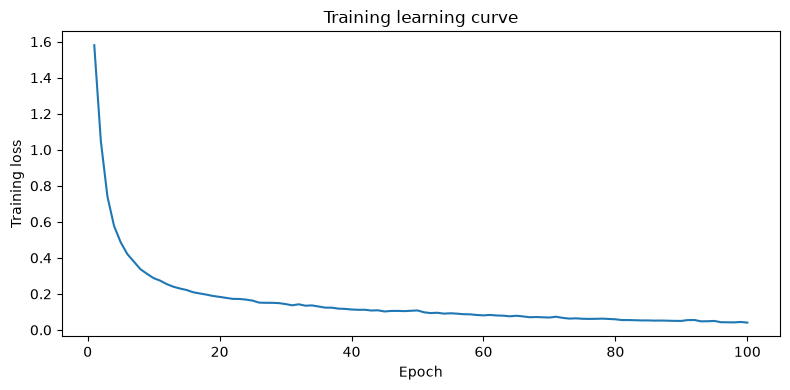

              precision    recall  f1-score   support

       BERHI       0.87      1.00      0.93        13
      DEGLET       0.80      0.80      0.80        20
       DOKOL       0.95      0.95      0.95        41
       IRAQI       1.00      0.86      0.92        14
      ROTANA       0.94      1.00      0.97        33
      SAFAVI       0.98      1.00      0.99        40
       SOGAY       0.88      0.74      0.80        19

    accuracy                           0.93       180
   macro avg       0.92      0.91      0.91       180
weighted avg       0.93      0.93      0.93       180

Test accuracy: 0.9278


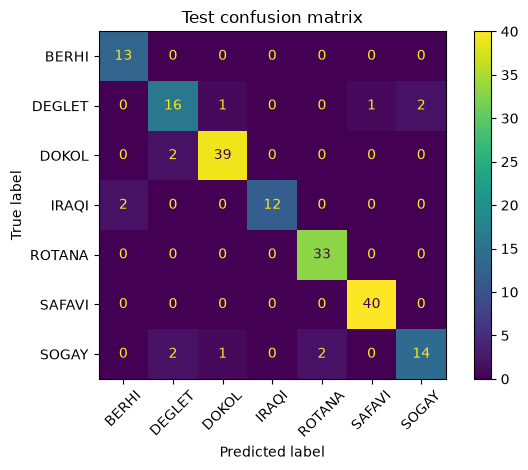

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score

plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), train_losses)
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Training learning curve")
plt.tight_layout()
plt.show()

model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        y_true.extend(yb.tolist())
        y_pred.extend(model(xb).argmax(dim=1).tolist())
class_names = le.classes_

print(classification_report(y_true, y_pred, labels=list(range(len(class_names))), target_names=class_names, zero_division=0))
print(f"Test accuracy: {accuracy_score(y_true, y_pred):.4f}")
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=list(range(len(class_names))), display_labels=class_names, xticks_rotation=45)
plt.title("Test confusion matrix")
plt.tight_layout()
plt.show()
